# 01 · Qualidade e tratamento da base de NPS

**Projeto:** Tech Challenge Fase 1 · Case NPS Preditivo
**Objetivo deste notebook:** garantir que a base é confiável o suficiente para sustentar decisões de negócio, documentar cada decisão de tratamento e gerar a base analítica usada na EDA (`data/processed/nps_tratado.csv`).

> **Resumo para quem tem 1 minuto**
> - A base tem **2.500 pedidos, 19 colunas, zero nulos e zero duplicados**: estruturalmente está limpa.
> - Cada cliente aparece **uma única vez** (1 cliente = 1 pedido). Não há histórico por cliente; o único sinal de relacionamento é o tempo de casa.
> - A nota de NPS vem **com casas decimais** (ex.: 6,9), o que não acontece numa pesquisa NPS real (0 a 10, inteiros). Adotamos cortes contínuos (≥ 9 promotor; 7 a < 9 neutro; < 7 detrator) e mostramos que a conclusão **não muda** se arredondarmos.
> - Encontramos **inconsistências lógicas** em parte dos registros (ex.: 4,8% com atraso maior que o prazo total). Decisão: **sinalizar, não apagar**, e testar se os achados mudam sem esses registros. **Não mudam.**
> - `repeat_purchase_30d` e `csat_internal_score` são **consequências** da satisfação, medidas depois ou junto do NPS. Ficam fora da lista de “fatores que explicam o NPS” para evitar conclusões circulares.

In [1]:
# Configuração do ambiente: permite importar o pacote src/ a partir da pasta notebooks/
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config as cfg
from src.data_prep import (load_raw, validate_schema, audit_consistency,
                           build_processed_dataset)
from src.metrics import classify_nps, nps_value
from src.viz import set_style, subtitle, save

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Primeira leitura da base

Leitura da base **exatamente como recebida**, sem nenhuma transformação, para registrar o ponto de partida.

In [2]:
raw = load_raw()
print(f"Linhas: {raw.shape[0]:,} | Colunas: {raw.shape[1]}")
raw.head()

Linhas: 2,500 | Colunas: 19


,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.90,0,3,6.50
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.40,0,3,0.00
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.80,0,7,1.50
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.90,0,4,0.30
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.10,0,3,7.90


In [3]:
# Tipos e memória: confirma que nenhuma coluna numérica foi lida como texto
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   str    
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64  
 14  res

## 2. Validação de esquema: colunas, nulos e faixas plausíveis

Cada coluna é comparada ao dicionário de dados e a faixas mínimas e máximas que fazem sentido para o negócio (ex.: idade ≥ 18, nota de 0 a 10, parcelas até 24). As regras estão em `src/data_prep.py` (`EXPECTED_SCHEMA`).

In [4]:
schema_report = validate_schema(raw)
schema_report

,coluna,presente,tipo_esperado,nulos,abaixo_do_minimo,acima_do_maximo,min,max
0,customer_id,True,int,0,0,0,1.00,"2,500.00"
1,customer_age,True,int,0,0,0,18.00,69.00
2,customer_region,True,category,0,0,0,NaN,NaN
3,customer_tenure_months,True,int,0,0,0,1.00,119.00
4,order_id,True,int,0,0,0,"50,001.00","52,500.00"
5,order_value,True,float,0,0,0,7.76,"1,983.81"
6,items_quantity,True,int,0,0,0,1.00,6.00
7,discount_value,True,float,0,0,0,0.02,230.33
8,payment_installments,True,int,0,0,0,1.00,11.00
9,delivery_time_days,True,int,0,0,0,2.00,14.00


**Leitura:** todas as 19 colunas do dicionário estão presentes, não há valores nulos e nenhum valor está fora das faixas plausíveis. Não é necessário imputar dados.

## 3. Granularidade: o que é uma linha?

Entender a granularidade evita erros clássicos (ex.: contar o mesmo cliente duas vezes, ou somar NPS de pedidos de um mesmo cliente).

In [5]:
granularity = pd.Series({
    "linhas": len(raw),
    "customer_id únicos": raw["customer_id"].nunique(),
    "order_id únicos": raw["order_id"].nunique(),
    "linhas 100% duplicadas": int(raw.duplicated().sum()),
})
granularity

linhas                    2500
customer_id únicos        2500
order_id únicos           2500
linhas 100% duplicadas       0
dtype: int64

**Leitura:** 1 linha = 1 cliente = 1 pedido = 1 resposta de NPS. Consequências práticas:

- Não há como observar a **evolução** de um mesmo cliente ao longo do tempo (não existe série histórica por cliente).
- Também **não há data do pedido**: não conseguimos analisar sazonalidade, tendência ou picos operacionais (ex.: Black Friday). Isso é uma limitação registrada para o negócio.

## 4. A variável alvo: `nps_score`

Antes de analisar o que explica a satisfação, é preciso entender como ela foi medida.

In [6]:
target = raw[cfg.TARGET_COL]
print(target.describe().round(2).to_string())
print(f"\nValores distintos: {target.nunique()}")
print(f"Notas com casa decimal (não inteiras): {(target % 1 != 0).mean():.1%}")
print(f"Notas exatamente 0: {(target == 0).sum()} | exatamente 10: {(target == 10).sum()}")

count   2,500.00
mean        4.38
std         2.51
min         0.00
25%         2.60
50%         4.40
75%         6.10
max        10.00

Valores distintos: 101
Notas com casa decimal (não inteiras): 83.0%
Notas exatamente 0: 158 | exatamente 10: 42


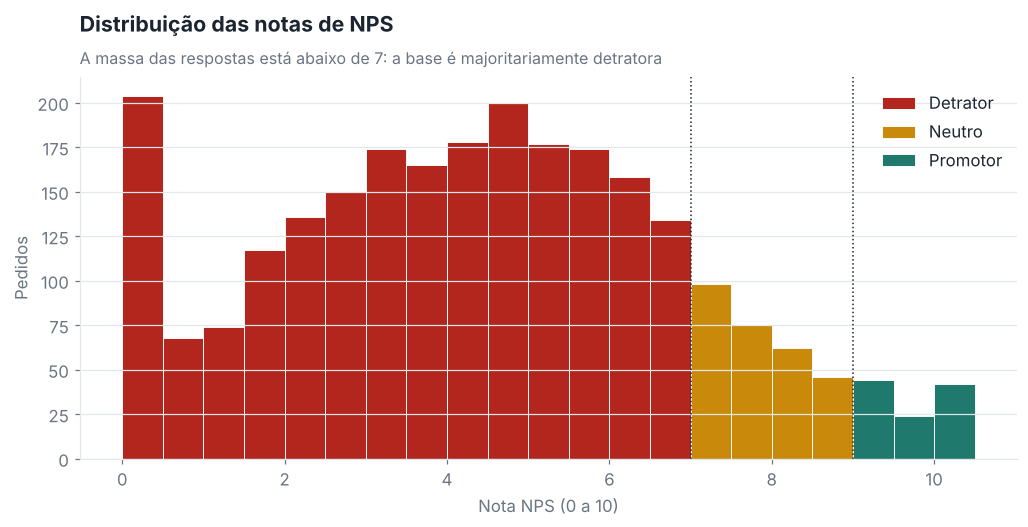

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
bins = np.arange(0, 10.6, 0.5)
category = classify_nps(target)
for cat in cfg.NPS_CATEGORY_ORDER:
    ax.hist(target[category == cat], bins=bins, color=cfg.CATEGORY_COLORS[cat],
            label=cat, edgecolor="white", linewidth=0.6)
ax.axvline(cfg.PASSIVE_THRESHOLD, color=cfg.COLORS["ink"], ls=":", lw=1)
ax.axvline(cfg.PROMOTER_THRESHOLD, color=cfg.COLORS["ink"], ls=":", lw=1)
ax.set_title("Distribuição das notas de NPS")
subtitle(ax, "A massa das respostas está abaixo de 7: a base é majoritariamente detratora")
ax.set_xlabel("Nota NPS (0 a 10)"); ax.set_ylabel("Pedidos"); ax.legend()
save(fig, "01_distribuicao_nps")
plt.show()

### 4.1 Teste de sensibilidade: notas decimais

Na metodologia oficial, o cliente responde um **inteiro de 0 a 10**. Como aqui a nota é contínua, há duas formas razoáveis de classificar:

1. **Cortes contínuos** (adotado): promotor ≥ 9,0; neutro de 7,0 a 8,9; detrator < 7,0.
2. **Arredondar** para o inteiro mais próximo e aplicar a regra oficial.

Se a escolha mudasse a conclusão, isso seria um risco relevante. Vamos testar.

In [8]:
rounded = target.round()
sensitivity = pd.DataFrame({
    "Cortes contínuos (adotado)": classify_nps(target).value_counts(normalize=True) * 100,
    "Nota arredondada": classify_nps(rounded).value_counts(normalize=True) * 100,
}).reindex(cfg.NPS_CATEGORY_ORDER)
sensitivity.loc["NPS"] = [nps_value(target), nps_value(rounded)]
sensitivity.round(1)

,Cortes contínuos (adotado),Nota arredondada
nps_category,,
Detrator,84.40,80.00
Neutro,11.20,14.00
Promotor,4.40,5.90
NPS,-80.00,-74.10


**Leitura:** o NPS fica entre **−80** (adotado) e **−74** (arredondado). Em qualquer critério, a empresa tem um NPS **profundamente negativo**, com mais de 80% de detratores. A escolha metodológica não altera o diagnóstico; seguimos com os cortes contínuos, que não descartam informação.

## 5. Consistência de negócio

Uma base pode não ter nulos e ainda assim conter registros **logicamente impossíveis**. Testamos regras de negócio explícitas (definidas em `DATA_QUALITY_RULES`).

In [9]:
quality_report = audit_consistency(raw)
quality_report

,regra,descricao,registros,%_base
0,dq_delay_gt_delivery_time,Dias de atraso maiores que o prazo total de en...,121,4.80
1,dq_discount_gt_order_value,Desconto maior que o valor do pedido,35,1.40
2,dq_resolution_without_contact,Tempo de resolução > 0 sem nenhum contato com ...,511,20.40
3,dq_complaints_gt_contacts,Mais reclamações do que contatos com o atendim...,2428,97.10
4,dq_csat_zero,CSAT interno exatamente 0 (possível valor padr...,462,18.50
5,dq_duplicated_order,order_id duplicado,0,0.00


**Interpretação de cada regra e decisão tomada**

| Regra | O que significa | Diagnóstico | Decisão |
|---|---|---|---|
| Atraso > prazo total (4,8%) | Um pedido não pode atrasar mais dias do que levou para chegar, se o prazo total inclui o atraso | Erro de registro **ou** definições diferentes das duas colunas | Sinalizar como **crítico** e testar robustez |
| Desconto > valor do pedido (1,4%) | Desconto maior que o próprio pedido | `order_value` pode ser valor **líquido** (já com desconto) | Sinalizar como **crítico** e testar robustez |
| Resolução sem contato (20,4%) | Tempo de resolução preenchido sem contato com o SAC | Problemas podem ser resolvidos por outros canais (ex.: logística reversa automática) | Manter; levar como **dúvida de definição** ao dono do dado |
| Reclamações > contatos (97,1%) | Mais reclamações do que contatos | Quase toda a base: indica que reclamações vêm de **outros canais** (marketplace, Reclame Aqui, avaliações), não é erro | Manter; tratar as duas variáveis como sinais distintos |
| CSAT = 0 (18,5%) | Nota interna exatamente zero | Pode ser nota real ou valor padrão para “não respondeu” | Manter; CSAT não entra como fator explicativo (ver seção 7) |

**Por que não apagar?** Remover registros sem confirmação do dono do dado pode enviesar a análise. O caminho profissional é sinalizar, quantificar e verificar se os achados dependem desses registros.

## 6. Teste de robustez: os achados mudam sem os registros suspeitos?

Comparamos a correlação de cada fator com a nota NPS **na base completa** e **sem os registros com inconsistência crítica**. Usamos a correlação de Spearman, que mede se “quando um sobe, o outro tende a subir/descer”, sem exigir relação linear.

In [10]:
processed = build_processed_dataset()
clean_subset = processed[~processed["dq_critical"]]

def spearman_with_target(data):
    return data[cfg.DRIVER_COLS].corrwith(data[cfg.TARGET_COL], method="spearman")

robustness = pd.DataFrame({
    "base_completa": spearman_with_target(processed),
    "sem_inconsistencias": spearman_with_target(clean_subset),
})
robustness["diferenca"] = robustness["sem_inconsistencias"] - robustness["base_completa"]
robustness.index = [cfg.LABELS_PT[c] for c in robustness.index]
print(f"Registros com inconsistência crítica: {processed['dq_critical'].sum()} "
      f"({processed['dq_critical'].mean():.1%})")
robustness.sort_values("base_completa").round(3)

Registros com inconsistência crítica: 154 (6.2%)


,base_completa,sem_inconsistencias,diferenca
Dias de atraso,-0.59,-0.57,0.02
Reclamações,-0.49,-0.50,-0.01
Contatos com atendimento,-0.34,-0.34,-0.00
Tempo de resolução,-0.19,-0.19,-0.00
Valor do frete,-0.04,-0.04,0.00
Tempo de casa (meses),-0.01,-0.01,0.01
Idade do cliente,-0.01,-0.01,0.00
Prazo total de entrega,0.00,-0.07,-0.07
Qtd. de itens,0.01,0.01,0.00
Desconto,0.01,0.02,0.00


**Leitura:** os quatro fatores mais relevantes (atraso, reclamações, contatos e tempo de resolução) aparecem **na mesma ordem e com a mesma intensidade** nos dois cenários. A única variação perceptível é o prazo total de entrega (de 0,00 para −0,07), e ela é um efeito do próprio filtro: ao retirar os pedidos com atraso maior que o prazo, retiramos justamente pedidos curtos com muito atraso, o que cria uma relação artificial. Mesmo assim, segue sendo uma relação fraca. Conclusão: os achados são robustos; seguimos com a base completa (maior volume, mais precisão) e mantemos as flags para auditoria.

## 7. Variáveis que **não** podem explicar o NPS: `repeat_purchase_30d` e `csat_internal_score`

Este é o ponto de maior risco conceitual da base.

- **Recompra em 30 dias** acontece **depois** da pesquisa. Ela é **consequência** da satisfação, não causa. Usá-la para “explicar” o NPS seria raciocínio circular; num modelo preditivo, seria vazamento de informação (o modelo “colaria” com uma informação que não existe no momento da previsão).
- **CSAT interno** é **outra medida de satisfação**. Ela é útil como termômetro complementar, mas dizer que “o CSAT explica o NPS” é dizer que “satisfação explica satisfação”.

In [11]:
# Recompra por faixa de nota: mostra o elo NPS -> receita (e um padrão suspeito)
repeat_by_score = (processed
    .groupby(pd.cut(processed["nps_score"], [-0.1, 6.99, 7.99, 8.99, 10],
                    labels=["0 a 6,9", "7 a 7,9", "8 a 8,9", "9 a 10"]), observed=True)
    ["repeat_purchase_30d"].agg(pedidos="size", taxa_recompra="mean"))
repeat_by_score["taxa_recompra"] = (repeat_by_score["taxa_recompra"] * 100).round(1)
repeat_by_score

,pedidos,taxa_recompra
nps_score,,
"0 a 6,9",2109,0.00
"7 a 7,9",173,0.00
"8 a 8,9",108,100.00
9 a 10,110,100.00


**Leitura e alerta:** na base, a recompra ocorre em **100%** dos casos com nota ≥ 8 e em **0%** abaixo de 8. Na vida real, a relação NPS → recompra é forte mas **nunca determinística**. Isso indica que a base provavelmente foi **gerada com uma regra** (dado sintético ou simulado). Implicação: usamos esse achado para mostrar a **direção** do impacto financeiro (satisfação puxa recompra), mas **não** a magnitude exata.

In [12]:
csat_corr = processed[["csat_internal_score", "nps_score", "resolution_time_days",
                       "delivery_delay_days", "complaints_count"]].corr(method="spearman")
csat_corr.loc[["csat_internal_score"]].round(2)

,csat_internal_score,nps_score,resolution_time_days,delivery_delay_days,complaints_count
csat_internal_score,1.00,0.56,-0.74,-0.46,-0.38


**Leitura:** o CSAT interno anda junto com o NPS (ρ ≈ 0,56), mas se relaciona muito mais com o **tempo de resolução** (ρ ≈ −0,74): ele parece medir a satisfação com o **atendimento**, não com a experiência inteira. É um bom indicador antecedente para a operação acompanhar, mas não substitui o NPS.

## 8. Valores extremos (outliers)

Verificamos valores extremos pela regra do intervalo interquartil (IQR). Em dados de negócio, “extremo” não significa “errado”: um pedido de R$ 1.900 é perfeitamente plausível.

In [13]:
numeric_cols = [c for c in cfg.DRIVER_COLS]
q1, q3 = processed[numeric_cols].quantile(0.25), processed[numeric_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((processed[numeric_cols] < q1 - 1.5 * iqr) | (processed[numeric_cols] > q3 + 1.5 * iqr))
outlier_table = pd.DataFrame({
    "registros_extremos": outliers.sum(),
    "%_base": (outliers.mean() * 100).round(1),
    "max_observado": processed[numeric_cols].max(),
}).rename(index=cfg.LABELS_PT)
outlier_table[outlier_table["registros_extremos"] > 0]

,registros_extremos,%_base,max_observado
Valor do pedido,84,3.40,"1,983.81"
Desconto,125,5.00,230.33
Dias de atraso,17,0.70,8.00
Valor do frete,12,0.50,76.13
Contatos com atendimento,176,7.00,7.00
Reclamações,29,1.20,11.00


**Decisão:** manter todos os valores. Os extremos são de valor do pedido, desconto, contatos e atrasos longos, todos possíveis no negócio. Atrasos e contatos extremos, em particular, são **exatamente** os casos que mais interessam à análise; removê-los esconderia o problema.

## 9. Base analítica: variáveis criadas para a leitura de negócio

As colunas originais são preservadas. Criamos variáveis auxiliares (em `add_business_features`) para facilitar a comunicação com o negócio:

| Variável criada | Para que serve |
|---|---|
| `nps_category`, `is_detractor`, `is_promoter` | Classificação oficial do NPS |
| `delay_band`, `complaints_band`, `contacts_band`, `resolution_band` | Faixas operacionais para encontrar pontos de ruptura |
| `age_band`, `tenure_band`, `order_value_band` | Perfis de cliente e de pedido |
| `discount_pct`, `freight_pct` | Desconto e frete em proporção do pedido (comparáveis entre tickets) |
| `is_late` | Pedido entregue fora do prazo prometido |
| `frictionless_journey` | Jornada sem atrito: atraso ≤ 1 dia **e** no máximo 1 reclamação |
| `dq_*` | Flags de qualidade de dados (auditoria) |

In [14]:
cfg.DATA_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
processed.to_csv(cfg.DATA_PROCESSED_PATH, index=False)
pd.concat([quality_report.assign(tipo="consistencia")], ignore_index=True)\
  .to_csv(cfg.QUALITY_REPORT_PATH, index=False)

print(f"Base tratada salva em: {cfg.DATA_PROCESSED_PATH.relative_to(cfg.ROOT_DIR)}")
print(f"Relatório de qualidade salvo em: {cfg.QUALITY_REPORT_PATH.relative_to(cfg.ROOT_DIR)}")
print(f"Dimensões finais: {processed.shape}")

Base tratada salva em: data/processed/nps_tratado.csv
Relatório de qualidade salvo em: reports/data_quality_report.csv
Dimensões finais: (2500, 39)


## 10. Conclusões e pendências com o dono do dado

**Conclusões**
1. A base é estruturalmente íntegra e suficiente para a análise exploratória.
2. As inconsistências encontradas **não alteram** os achados (teste de robustez).
3. A nota decimal **não altera** o diagnóstico de NPS fortemente negativo.
4. Recompra e CSAT ficam reservados para medir **consequência**, não causa.

**Perguntas a levar ao dono do dado (antes de qualquer uso em produção)**
1. `delivery_time_days` inclui os dias de atraso? Por que há atrasos maiores que o prazo total?
2. `order_value` é bruto ou líquido de desconto?
3. De quais canais vêm as `complaints_count`? Por que superam os contatos com o atendimento?
4. CSAT = 0 é nota real ou “não respondeu”?
5. A base é real, amostrada ou simulada? A relação recompra × nota é determinística.
6. É possível obter a **data do pedido** e da resposta, e o **prazo prometido** no checkout?